# Taller · De los datos a un dashboard publicado

**Programación — ADMI 1301 · Taller resuelto sobre el notebook original**

Base: 2.000 ventas de papelerías en 2025. Cuatro partes: seis gráficos, subplots (2 × 3), iteración de prompts de estilo con Gemini y tres hallazgos.

**Nota sobre la ejecución:** esta copia incluye el CSV original comprimido dentro del notebook para que se pueda ejecutar sin subir ningún archivo. En la Parte C se usarán las respuestas reales de Gemini si configuras el secreto `GEMINI_API_KEY` en Colab; en caso contrario, las versiones **v1 y v2 serán demostraciones locales**, claramente identificadas, que NO equivalen a haber probado Gemini.

**Trabajo realizado sobre la guía original.** Las soluciones están organizadas por ejercicio y sus verificaciones se ejecutaron correctamente.


## 0. Preparación
La base `ventas_papelerias_2025.csv` suministrada está incluida en el notebook; basta ejecutar esta celda.


In [191]:
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import base64, gzip, io

# CSV ORIGINAL incluido para que el notebook funcione sin subir archivos.
# Es la misma base de 2.000 ventas del profesor; no se alteran sus registros.
DATOS_CSV_COMPRIMIDOS = (
    '...'
    'Ur2N6gYV/KD2dUUXn9+r//T/A5mtlpDBNwMA'
)
df = pd.read_csv(io.BytesIO(gzip.decompress(base64.b64decode(DATOS_CSV_COMPRIMIDOS))))
df["fecha"] = pd.to_datetime(df["fecha"])
df["mes"] = df["fecha"].dt.month
assert df.shape == (2000, 14), "La base debe contener 2.000 ventas y 14 columnas contando 'mes'."
print("Base cargada:", len(df), "ventas de 2025")
display(df.head())


Base cargada: 2000 ventas de 2025


,id_venta,fecha,ciudad,canal,segmento,vendedor,producto,categoria,metodo_pago,cantidad,precio_unitario,descuento,total,mes
0,V0001,2025-01-01,Cali,Tienda,Corporativo,Julián Cortés,Resma carta,Papel,Transferencia,6,18000,0.10,97200,1
1,V0002,2025-01-01,Medellín,Telefónico,Corporativo,Andrés Rojas,Carpeta,Organización,Transferencia,21,2500,0.00,52500,1
2,V0003,2025-01-01,Barranquilla,Telefónico,Mayorista,Mateo Peña,Cuaderno,Papel,Transferencia,65,3500,0.10,204750,1
3,V0004,2025-01-02,Bucaramanga,Online,Minorista,Isabela Mora,Colores x12,Arte,Tarjeta,6,8500,0.00,51000,1
4,V0005,2025-01-02,Medellín,Telefónico,Mayorista,Andrés Rojas,Esfero,Escritura,Tarjeta,67,1200,0.15,68340,1


**Conoce tus datos** antes de graficar: cuántas filas hay, qué columnas, qué valores tiene cada categoría.

In [192]:
print(df.shape)
df.info()
for col in ["ciudad", "canal", "segmento", "categoria", "metodo_pago"]:
    print(col, "->", sorted(df[col].unique()))

(2000, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   id_venta         2000 non-null   object        
 1   fecha            2000 non-null   datetime64[ns]
 2   ciudad           2000 non-null   object        
 3   canal            2000 non-null   object        
 4   segmento         2000 non-null   object        
 5   vendedor         2000 non-null   object        
 6   producto         2000 non-null   object        
 7   categoria        2000 non-null   object        
 8   metodo_pago      2000 non-null   object        
 9   cantidad         2000 non-null   int64         
 10  precio_unitario  2000 non-null   int64         
 11  descuento        2000 non-null   float64       
 12  total            2000 non-null   int64         
 13  mes              2000 non-null   int32         
dtypes: datetime64[ns](1), float64

---
# Parte A · Seis gráficos
En cada ejercicio: **(1)** prepara una tabla con `groupby`, `crosstab` o `pivot_table`, **(2)** guárdala en la variable indicada, **(3)** grafícala. Ponle **título** a cada gráfico.

### Ejercicio 1 · Top 5 de productos *(barras horizontales)*
**Contexto.** La gerente de compras debe decidir en qué productos concentrar el inventario del próximo año.

**Tarea.** Calcula los ingresos (`total`) por `producto`, quédate con los **5 mayores** y grafícalos en barras horizontales. Guarda la tabla en **`top_productos`**.

*Herramientas:* `groupby`, `sum`, `sort_values`, `head`, `.plot.barh()`

Ingresos de los 5 productos principales:


,total
producto,
Cuaderno,20712345
Block de notas,14292347
Resma carta,13133570
Marcador,10020786
Colores x12,9419625


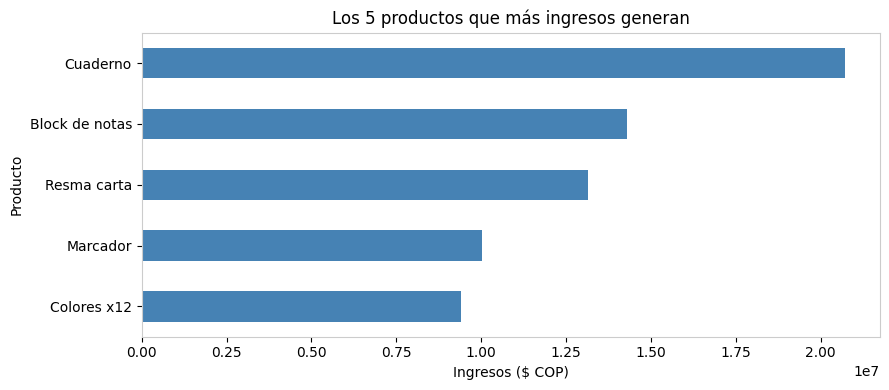

Ejercicio 1 correcto ✔


In [193]:
# Ejercicio 1: top 5 de productos por ingresos
# Agrupamos, sumamos, ordenamos de mayor a menor y tomamos 5.
top_productos = (df.groupby("producto")["total"].sum()
                 .sort_values(ascending=False).head(5))
print("Ingresos de los 5 productos principales:")
display(top_productos)
ax = top_productos.sort_values().plot.barh(figsize=(9, 4), color="steelblue")
ax.set_title("Los 5 productos que más ingresos generan")
ax.set_xlabel("Ingresos ($ COP)")
ax.set_ylabel("Producto")
plt.tight_layout()
plt.show()
assert len(top_productos) == 5 and top_productos.index[0] == "Cuaderno"
print("Ejercicio 1 correcto ✔")


### Ejercicio 2 · Ingresos mes a mes: Bogotá vs Medellín *(líneas)*
**Contexto.** La dirección regional quiere comparar la evolución de sus dos ciudades principales durante el año.

**Tarea.** **Selecciona** solo las ventas de Bogotá y Medellín (`isin`). Con una **tabla dinámica** pon los meses en las filas, las ciudades en las columnas y la suma de `total` como valores. Guárdala en **`ing_mes_ciudad`** y grafícala como líneas con marcadores.

*Herramientas:* filtrado con `isin`, `pivot_table`, `.plot.line(marker="o")`

Tabla de ingresos por mes y ciudad:


ciudad,Bogotá,Medellín
mes,,
1,4815405,3504905
2,3037200,2262080
3,3629385,1342665
4,3117990,1107910
5,3937775,3164730
6,1631810,2848235
7,2781218,2771377
8,3706217,4092446
9,2245001,969551


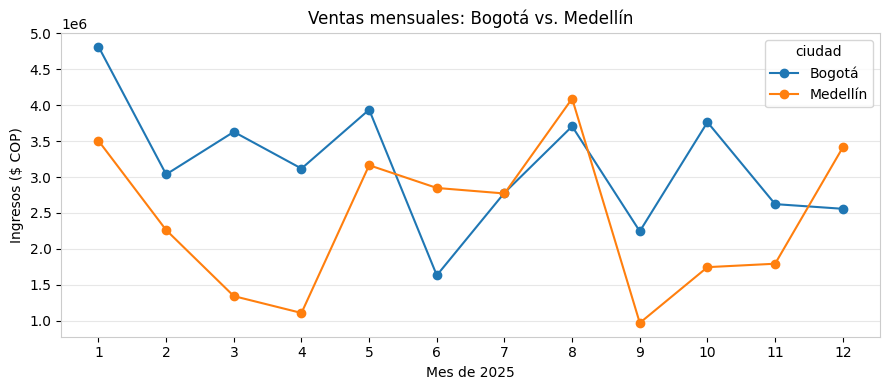

Ejercicio 2 correcto ✔


In [194]:
# Ejercicio 2: ingresos mensuales de Bogotá y Medellín
filtro_ciudades = df[df["ciudad"].isin(["Bogotá", "Medellín"])]
ing_mes_ciudad = filtro_ciudades.pivot_table(
    index="mes", columns="ciudad", values="total", aggfunc="sum")
print("Tabla de ingresos por mes y ciudad:")
display(ing_mes_ciudad)
ax = ing_mes_ciudad.plot.line(marker="o", figsize=(9, 4))
ax.set_title("Ventas mensuales: Bogotá vs. Medellín")
ax.set_xlabel("Mes de 2025")
ax.set_ylabel("Ingresos ($ COP)")
ax.set_xticks(range(1,13))
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
assert ing_mes_ciudad.shape == (12,2)
assert set(ing_mes_ciudad.columns) == {"Bogotá","Medellín"}
print("Ejercicio 2 correcto ✔")


### Ejercicio 3 · ¿Por qué canal se vende más? *(gráfico de pie)*
**Contexto.** La empresa evalúa si invierte más en su tienda online o en la atención telefónica.

**Tarea.** Calcula los ingresos totales por `canal`, guárdalos en **`ing_canal`** y grafica la participación de cada canal con un gráfico de pie que muestre los **porcentajes con un decimal**.

*Herramientas:* `groupby`, `.plot.pie(autopct=...)`

Ingresos por canal:


,total
canal,
Telefónico,61450716
Tienda,34329722
Online,22887574


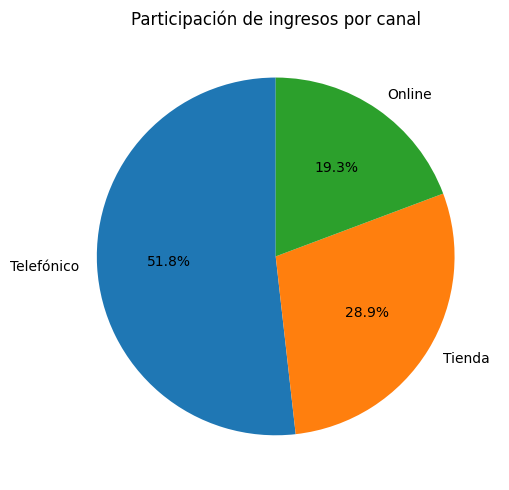

Ejercicio 3 correcto ✔


In [195]:
# Ejercicio 3: participación en ingresos por canal
ing_canal = df.groupby("canal")["total"].sum().sort_values(ascending=False)
print("Ingresos por canal:")
display(ing_canal)
ax = ing_canal.plot.pie(autopct="%1.1f%%", figsize=(6, 5), startangle=90)
ax.set_title("Participación de ingresos por canal")
ax.set_ylabel("")
plt.tight_layout()
plt.show()
assert ing_canal.idxmax() == "Telefónico"
assert ing_canal["Telefónico"] / ing_canal.sum() > 0.5
print("Ejercicio 3 correcto ✔")


### Ejercicio 4 · ¿Cada segmento compra lo mismo? *(barras apiladas)*
**Contexto.** El área comercial sospecha que los clientes corporativos compran productos distintos a los minoristas.

**Tarea.** Con `pd.crosstab` cuenta las ventas por `segmento` (filas) y `categoria` (columnas), **normalizadas por fila** y expresadas en **porcentaje** (de 0 a 100). Guarda la tabla en **`tabla_seg_cat`** y grafícala en barras **apiladas**.

*Herramientas:* `pd.crosstab(..., normalize="index")`, `.plot.bar(stacked=True)`

Porcentajes de ventas por segmento y categoría:


categoria,Arte,Corrección,Escritura,Organización,Papel
segmento,,,,,
Corporativo,2.8,5.4,30.2,23.3,38.2
Mayorista,5.6,12.2,54.0,5.6,22.5
Minorista,12.1,12.8,55.8,4.3,15.2


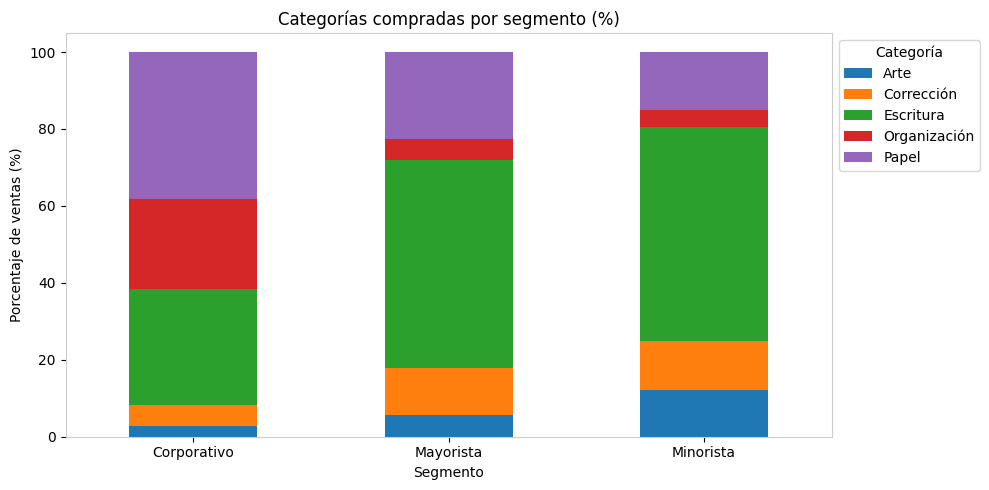

Ejercicio 4 correcto ✔


In [196]:
# Ejercicio 4: proporción de categorías dentro de cada segmento
# normalize='index' hace que cada fila sume 1; multiplicamos por 100.
tabla_seg_cat = pd.crosstab(df["segmento"], df["categoria"], normalize="index") * 100
print("Porcentajes de ventas por segmento y categoría:")
display(tabla_seg_cat.round(1))
ax = tabla_seg_cat.plot.bar(stacked=True, figsize=(10, 5))
ax.set_title("Categorías compradas por segmento (%)")
ax.set_xlabel("Segmento")
ax.set_ylabel("Porcentaje de ventas (%)")
ax.legend(title="Categoría", bbox_to_anchor=(1,1), loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
assert tabla_seg_cat.shape == (3,5)
assert all(abs(tabla_seg_cat.sum(axis=1)-100)<1e-7)
print("Ejercicio 4 correcto ✔")


### Ejercicio 5 · Productividad de los vendedores *(dispersión)*
**Contexto.** Recursos humanos revisa qué vendedores concretan más ventas y cuáles venden tickets más altos.

**Tarea.** Con `groupby` por `vendedor` y `ciudad`, calcula para cada vendedor el **número de ventas** (`n_ventas`) y el **valor promedio de sus ventas** (`ticket_prom`). Guarda la tabla en **`vend`** (con índice normal: usa `reset_index()`). Haz una dispersión (`n_ventas` en X, `ticket_prom` en Y) con un **color por ciudad** y leyenda.

*Herramientas:* `groupby().agg(nombre=("columna", "función"))`, `reset_index`, `plt.scatter` dentro de un `for`

Productividad de vendedores:


,vendedor,ciudad,n_ventas,ticket_prom
6,Laura Gómez,Bogotá,312,58564.371795
5,Julián Cortés,Cali,215,56389.920930
10,Sofía Mejía,Medellín,215,53688.744186
1,Camilo Pardo,Bogotá,210,54276.595238
0,Andrés Rojas,Medellín,192,60729.104167
7,Mateo Peña,Barranquilla,165,60888.484848
8,Paula Vargas,Cali,136,76343.213235
2,Daniela Ríos,Bogotá,130,62903.423077
11,Valeria Ortiz,Barranquilla,122,49982.418033
4,Isabela Mora,Bucaramanga,108,65873.037037


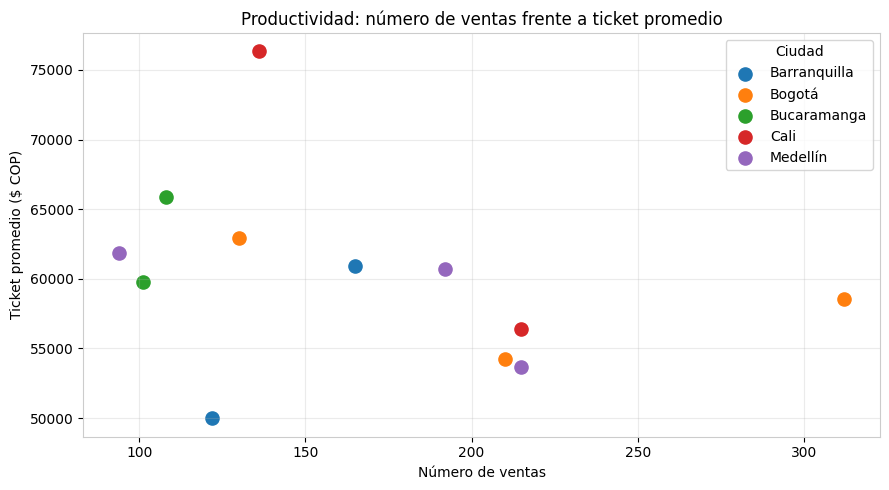

Ejercicio 5 correcto ✔


In [197]:
# Ejercicio 5: ventas realizadas y ticket promedio de cada vendedor
vend = df.groupby(["vendedor", "ciudad"]).agg(
    n_ventas=("id_venta", "count"),
    ticket_prom=("total", "mean")
).reset_index()
print("Productividad de vendedores:")
display(vend.sort_values("n_ventas", ascending=False))
plt.figure(figsize=(9,5))
for ciudad in sorted(vend["ciudad"].unique()):
    datos_ciudad = vend[vend["ciudad"] == ciudad]
    plt.scatter(datos_ciudad["n_ventas"], datos_ciudad["ticket_prom"], label=ciudad, s=90)
plt.title("Productividad: número de ventas frente a ticket promedio")
plt.xlabel("Número de ventas")
plt.ylabel("Ticket promedio ($ COP)")
plt.legend(title="Ciudad")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()
assert len(vend)==12
assert vend["n_ventas"].sum()==2000
print("Ejercicio 5 correcto ✔")


### Ejercicio 6 · ¿Qué tan grandes son las ventas de cada segmento? *(diagrama de cajas)*
**Contexto.** Para planear el segundo semestre, finanzas quiere ver cómo se distribuye el valor de las ventas por tipo de cliente.

**Tarea.** **Selecciona** solo las ventas del **segundo semestre** (`mes` de 7 a 12) y guárdalas en **`sem2`**. Haz un diagrama de cajas del `total` por `segmento`, **sin mostrar los valores atípicos** (`showfliers=False`).

*Herramientas:* filtro con `>=`, `.boxplot(column=..., by=...)`

Ventas del segundo semestre: 1050


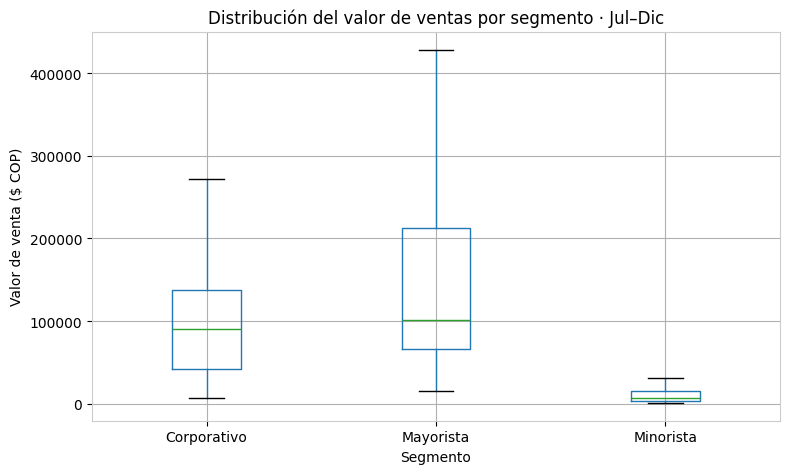

Ejercicio 6 correcto ✔


In [198]:
# Ejercicio 6: ventas del segundo semestre por segmento
sem2 = df[df["mes"] >= 7]
print("Ventas del segundo semestre:", len(sem2))
ax = sem2.boxplot(column="total", by="segmento", showfliers=False, figsize=(8, 5))
plt.suptitle("")
ax.set_title("Distribución del valor de ventas por segmento · Jul–Dic")
ax.set_xlabel("Segmento")
ax.set_ylabel("Valor de venta ($ COP)")
plt.tight_layout()
plt.show()
assert len(sem2)==1050
assert sem2["mes"].between(7,12).all()
print("Ejercicio 6 correcto ✔")


---
# Parte B · Todo en una sola figura (`subplots`)
### Ejercicio 7 · Organiza tus 6 gráficos en una cuadrícula de 2 × 3
**Contexto.** La gerente quiere ver todo en **una sola imagen** para presentarla en la junta.

**Tarea.** Crea una figura con `fig, axs = plt.subplots(2, 3, figsize=(18, 10))` y dibuja cada gráfico en su posición pasando **`ax=axs[fila, columna]`**. Agrega un título general con `fig.suptitle(...)` y termina con `plt.tight_layout()`.

**Importante:** escribe el código en la celda que empieza con `%%writefile figura_base.py` (así el programa guarda tu código en un archivo, que usarás en la Parte C). Luego ejecuta la celda siguiente (`%run -i figura_base.py`) para ver la figura.

*Pistas:* `plot.barh(ax=axs[0, 0])` · `plot.pie(...)` también acepta `ax` · para el boxplot: `boxplot(column=..., by=..., ax=...)` · para la dispersión: `axs[1, 1].scatter(...)`

In [199]:
%%writefile figura_base.py
# Ejercicio 7: los 6 gráficos juntos (Parte B del profesor)
fig, axs = plt.subplots(2, 3, figsize=(18, 10))

# Fila 1
(top_productos.sort_values().plot.barh(
    ax=axs[0, 0], title="Top 5 productos por ingresos", color="steelblue"))
axs[0, 0].set_xlabel("Ingresos ($)")
axs[0, 0].set_ylabel("Producto")

(ing_mes_ciudad.plot.line(
    ax=axs[0, 1], marker="o", title="Ingresos mensuales: Bogotá y Medellín"))
axs[0, 1].set_xlabel("Mes")
axs[0, 1].set_ylabel("Ingresos ($)")
axs[0, 1].set_xticks(range(1, 13))

(ing_canal.plot.pie(
    ax=axs[0, 2], autopct="%1.1f%%", title="Participación por canal"))
axs[0, 2].set_ylabel("")

# Fila 2
(tabla_seg_cat.plot.bar(
    ax=axs[1, 0], stacked=True, title="Categorías por segmento (%)"))
axs[1, 0].set_xlabel("Segmento")
axs[1, 0].set_ylabel("Porcentaje (%)")
axs[1, 0].tick_params(axis="x", rotation=0)
axs[1, 0].legend(fontsize=8)

for ciudad in sorted(vend["ciudad"].unique()):
    datos = vend[vend["ciudad"] == ciudad]
    axs[1, 1].scatter(datos["n_ventas"], datos["ticket_prom"], label=ciudad)
axs[1, 1].set_title("Productividad de vendedores")
axs[1, 1].set_xlabel("Número de ventas")
axs[1, 1].set_ylabel("Ticket promedio ($)")
axs[1, 1].legend(fontsize=7)

sem2.boxplot(column="total", by="segmento", ax=axs[1, 2], showfliers=False)
axs[1, 2].set_title("Valor de ventas por segmento · Jul–Dic")
axs[1, 2].set_xlabel("Segmento")
axs[1, 2].set_ylabel("Valor de venta ($)")

plt.suptitle("") # evita que pandas agregue un segundo título por boxplot
fig.suptitle("Ventas de la cadena de papelerías · 2025", fontsize=18)
plt.tight_layout(rect=(0, 0, 1, .95))


Overwriting figura_base.py


In [200]:
%run -i figura_base.py

In [201]:
# ✅ Verificación
assert len(fig.axes) >= 6, f"La figura debe tener 6 gráficos, tiene {len(fig.axes)}"
print("Ejercicio 7 correcto ✔")

Ejercicio 7 correcto ✔


---
# Parte C · Hazla ver bonita con prompts
Ahora **tú escribes el prompt y Gemini reescribe el código** de tu figura para que se vea profesional, casi como un dashboard.


### Herramientas de estilo y ejecución
Las funciones `embellecer(prompt, nombre)` y `mostrar(nombre)` se conservan. La primera usa **Gemini** si existe el secreto `GEMINI_API_KEY` en Colab; en caso contrario crea una **previsualización local** para que todo el notebook se ejecute y muestre ambos diseños.

**Importante:** las vistas locales son propuestas de diseño preparadas sin Gemini y no prueban que se haya hecho la iteración con IA. Si quieres acreditar esa parte tal como la pide la guía, crea un secreto `GEMINI_API_KEY` en el icono de llave de Colab, activa acceso y ejecuta otra vez las celdas v1 y v2. Nunca pegues la clave en el código público.


In [202]:
import re

VERSIONES = {}
ORIGEN_VERSION = {}
REGLAS_FIGURA = """
Reglas técnicas obligatorias:
- Usa solo pandas y matplotlib (y numpy si lo necesitas), sin otras librerías.
- Los datos ya están cargados en df; no leas archivos.
- Conserva los mismos seis análisis, tablas, cifras y el filtro Jul–Dic de 2025.
- La figura se llama fig y debe tener exactamente una cuadrícula de 2x3.
- Usa los nombres de variables originales: top_productos, ing_mes_ciudad, ing_canal, tabla_seg_cat, vend y sem2.
- No incluyas plt.show() ni guardes archivos; devuelve solo código Python completo.
"""

def extraer_codigo(texto):
    bloque = re.search(r"```(?:python)?\s*\n(.*?)```", texto, re.S)
    return bloque.group(1) if bloque else texto

def dibujar(codigo):
    import numpy as np
    plt.close("all")
    espacio = {"df":df, "pd":pd, "plt":plt, "np":np,
               "top_productos":top_productos, "ing_mes_ciudad":ing_mes_ciudad,
               "ing_canal":ing_canal, "tabla_seg_cat":tabla_seg_cat,
               "vend":vend, "sem2":sem2}
    exec(codigo, espacio)
    figura = espacio["fig"]
    assert len(figura.axes)==6, "Deben mantenerse seis gráficos."
    display(figura)
    plt.close(figura)

def embellecer(prompt, nombre, modelo="gemini-2.5-flash"):
    """Usa Gemini con Secret de Colab; si no hay clave usa PREVISUALIZACIÓN LOCAL."""
    codigo_actual = open("figura_base.py", encoding="utf-8").read()
    contenido = f"{prompt}\n\nCódigo actual:\n```python\n{codigo_actual}\n```{REGLAS_FIGURA}"
    clave = None
    try:
        from google.colab import userdata
        clave = userdata.get("GEMINI_API_KEY")
    except (ImportError, KeyError, Exception):
        pass
    codigo = None
    origen = "Previsualización local (sin Gemini)"
    if clave:
        try:
            from google import genai
            cliente = genai.Client(api_key=clave)
            respuesta = cliente.models.generate_content(model=modelo, contents=contenido)
            codigo_generado = extraer_codigo(respuesta.text)
            dibujar(codigo_generado)
            codigo = codigo_generado
            origen = "Gemini"
        except Exception as error:
            print("Gemini no devolvió una figura válida:", type(error).__name__, str(error)[:230])
    if codigo is None:
        print("Nota: se mostrará una versión visual LOCAL; no es una respuesta real de Gemini.")
        codigo = "VERSION_LOCAL = " + repr(nombre) + "\n" + ESTILO_LOCAL
        dibujar(codigo)
    VERSIONES[nombre] = codigo
    ORIGEN_VERSION[nombre] = origen
    print(f"✔ {nombre} guardada · origen: {origen}")

def mostrar(nombre):
    dibujar(VERSIONES[nombre])

ESTILO_LOCAL = 'import matplotlib.pyplot as plt\nimport matplotlib.ticker as mticker\n\n# Estos gráficos contienen exactamente las mismas agregaciones del taller.\nVERSION_LOCAL = VERSION_LOCAL  # v1 o v2, asignada al ejecutar el código\nmejora = (VERSION_LOCAL == "v2")\nfondo = "#f0f4f8" if not mejora else "#eff5f2"\ntexto = "#18334d" if not mejora else "#173b36"\nprincipal = "#2563a6" if not mejora else "#16806e"\nsecundario = "#d48238" if not mejora else "#d99638"\nciudades = {"Bogotá":"#234e75", "Medellín":"#e18c49", "Cali":"#5b9b73", "Barranquilla":"#bca146", "Bucaramanga":"#8064a2"}\n\ndef millones(x, pos=None):\n    return "$%.1f M" % (x / 1000000)\n\ndef miles(x, pos=None):\n    return "$%s mil" % format(x / 1000, ".0f")\n\nfig, axs = plt.subplots(2, 3, figsize=(20, 12.8) if mejora else (19, 12), facecolor=fondo)\nfig.subplots_adjust(wspace=.34, hspace=.45)\nfor ax in axs.flat:\n    ax.set_facecolor("white")\n    for lado in ("top", "right"):\n        ax.spines[lado].set_visible(False)\n    ax.tick_params(axis="both", labelsize=10 if mejora else 9, colors=texto)\n\n# 1. Productos, barras horizontales\nbarras = top_productos.sort_values().plot.barh(ax=axs[0,0], color=principal, legend=False)\naxs[0,0].set_title("Cuaderno lidera los ingresos", fontsize=14 if mejora else 12, fontweight="bold", loc="left", color=texto, pad=15)\naxs[0,0].set_xlabel("Ingresos (millones de COP)")\naxs[0,0].set_ylabel("")\naxs[0,0].xaxis.set_major_formatter(mticker.FuncFormatter(millones))\naxs[0,0].grid(axis="x", color="#d5dee4", alpha=.5)\naxs[0,0].set_axisbelow(True)\naxs[0,0].set_xlim(right=top_productos.max()*1.25)\nfor pos, valor in enumerate(top_productos.sort_values().values):\n    axs[0,0].text(valor + top_productos.max()*.025, pos, millones(valor), va="center", color=texto, fontsize=10)\n\n# 2. Comparación mensual por ciudad\nfor ciudad in ["Bogotá", "Medellín"]:\n    axs[0,1].plot(ing_mes_ciudad.index, ing_mes_ciudad[ciudad], marker="o", markersize=5, linewidth=2.5, color=ciudades[ciudad], label=ciudad)\naxs[0,1].set_title("Bogotá supera a Medellín en el año", fontsize=14 if mejora else 12, fontweight="bold", loc="left", color=texto, pad=15)\naxs[0,1].set_xlabel("Mes de 2025")\naxs[0,1].set_ylabel("Ingresos (millones de COP)")\naxs[0,1].set_xticks(range(1,13))\naxs[0,1].yaxis.set_major_formatter(mticker.FuncFormatter(millones))\naxs[0,1].grid(axis="y", alpha=.22)\naxs[0,1].legend(frameon=False, fontsize=9)\nif mejora:\n    pico_mes = ing_mes_ciudad["Bogotá"].idxmax()\n    pico = ing_mes_ciudad.loc[pico_mes, "Bogotá"]\n    axs[0,1].annotate("Pico Bogotá: %s" % millones(pico), (pico_mes, pico), xytext=(pico_mes+1.4, pico-800000), fontsize=9, color=texto, arrowprops={"arrowstyle":"->", "color":principal})\n\n# 3. Participación de canales, en v2 pasa de torta a dona.\ncolores_canales = [secundario, principal, "#7ab0b0"]\naxs[0,2].pie(ing_canal.values, labels=ing_canal.index, autopct="%1.1f%%", startangle=90, colors=colores_canales, wedgeprops={"width": .4 if mejora else 1, "edgecolor":"white", "linewidth":2}, pctdistance=.76, textprops={"fontsize":10})\naxs[0,2].set_title("Telefónico concentra el 51,8 %", fontsize=14 if mejora else 12, fontweight="bold", loc="left", color=texto, pad=15)\naxs[0,2].set_ylabel("")\n\n# 4. Categorías por segmento (cada fila suma 100%)\ntabla_seg_cat.plot.bar(ax=axs[1,0], stacked=True, color=["#5f98ab", "#d59c60", "#75a37f", "#887eb3", "#2d6179"], width=.75, legend=False)\naxs[1,0].set_title("Categorías: mezcla por segmento", fontsize=14 if mejora else 12, fontweight="bold", loc="left", color=texto, pad=15)\naxs[1,0].set_ylabel("Porcentaje de ventas (%)")\naxs[1,0].set_xlabel("")\naxs[1,0].tick_params(axis="x", rotation=0)\naxs[1,0].set_ylim(0, 110)\naxs[1,0].legend(tabla_seg_cat.columns, loc="upper left", bbox_to_anchor=(0,1.02), fontsize=7, ncol=3, frameon=False)\n\n# 5. Scatter: exactamente un punto por vendedor, color de ciudad\nfor ciudad in sorted(vend["ciudad"].unique()):\n    puntos = vend[vend["ciudad"]==ciudad]\n    axs[1,1].scatter(puntos["n_ventas"], puntos["ticket_prom"], label=ciudad, color=ciudades[ciudad], s=95 if mejora else 75, alpha=.85)\naxs[1,1].set_title("12 vendedores: ventas vs. ticket", fontsize=14 if mejora else 12, fontweight="bold", loc="left", color=texto, pad=15)\naxs[1,1].set_xlabel("Número de ventas")\naxs[1,1].set_ylabel("Ticket promedio (miles COP)")\naxs[1,1].yaxis.set_major_formatter(mticker.FuncFormatter(miles))\naxs[1,1].grid(alpha=.2)\naxs[1,1].legend(loc="best", fontsize=8, frameon=False, ncol=2)\n\n# 6. Diagrama de cajas del segundo semestre, sin outliers\ngrupos = sorted(sem2["segmento"].unique())\nvalores = [sem2.loc[sem2["segmento"]==g,"total"].values for g in grupos]\naxs[1,2].boxplot(valores, labels=grupos, showfliers=False, patch_artist=True, boxprops={"facecolor":principal, "alpha":.32, "edgecolor":principal}, medianprops={"color":secundario,"linewidth":2})\naxs[1,2].set_title("Jul–Dic: ventas por segmento", fontsize=14 if mejora else 12, fontweight="bold", loc="left", color=texto, pad=15)\naxs[1,2].set_xlabel("Segmento")\naxs[1,2].set_ylabel("Valor por venta (miles COP)")\naxs[1,2].yaxis.set_major_formatter(mticker.FuncFormatter(miles))\naxs[1,2].grid(axis="y", alpha=.2)\n\nfig.suptitle("CADENA DE PAPELERÍAS  |  DASHBOARD DE VENTAS 2025", fontsize=23 if mejora else 20, fontweight="bold", color=texto, y=.992)\nfig.text(.5,.948,"2.000 transacciones · cinco ciudades · cifras en pesos colombianos", ha="center", fontsize=11, color=texto)\nfig.text(.5,.022,"Fuente: ventas_papelerias_2025.csv · Ejercicios ADMI 1301", ha="center", fontsize=10, color=texto)\nfig.tight_layout(rect=(.015,.04,.985,.895), h_pad=3.4, w_pad=2.8)\n'


### Ejercicio 8 · Tu primer prompt de estilo
Completa las secciones de `prompt_v1`. Sé **específico**: "usa una paleta de azules y naranja" funciona mejor que "hazlo bonito".

- **PÚBLICO Y OBJETIVO:** quién verá la figura y para qué.
- **PALETA Y TIPOGRAFÍA:** colores (por ciudad, por producto…), fondo, tamaños de letra.
- **TÍTULOS:** que cada gráfico tenga un título que diga la **conclusión** (por ejemplo, "Bogotá lidera las ventas"), no solo el nombre.
- **EJES Y NÚMEROS:** formatos con separador de miles o "$ 12 M", etiquetas de ejes claras.
- **LIMPIEZA VISUAL:** quitar bordes y marcos innecesarios, cuadrícula suave, valores sobre las barras.

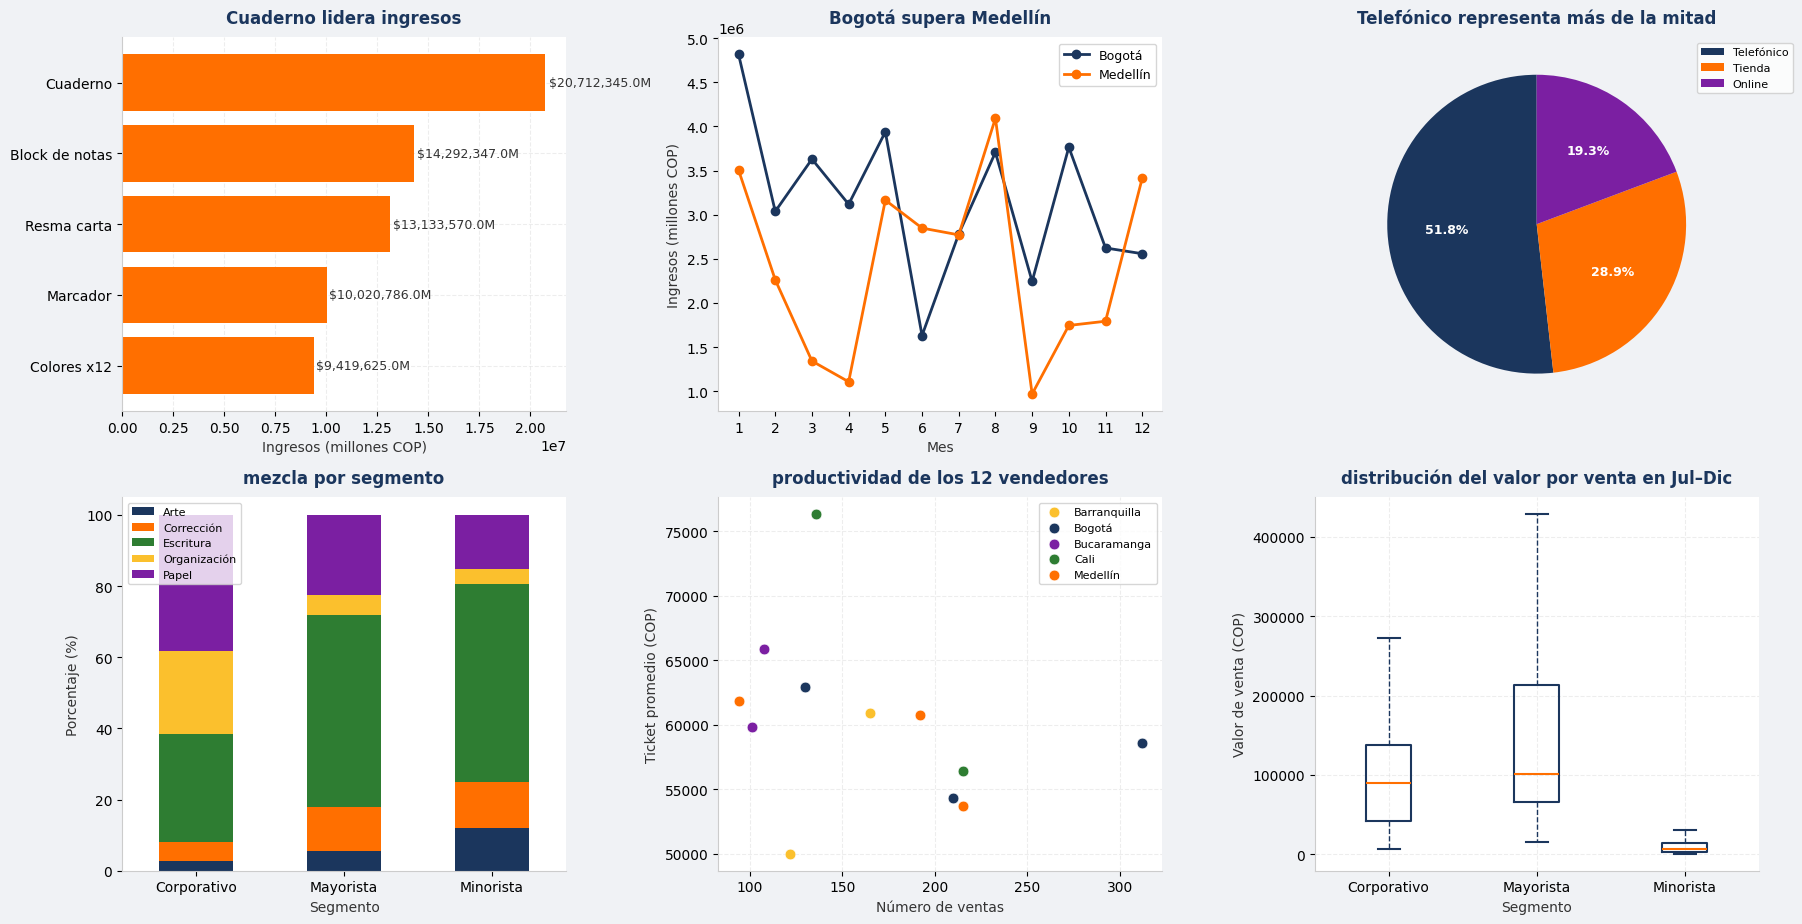

✔ v1 guardada · origen: Gemini


In [203]:
prompt_v1 = """
PÚBLICO Y OBJETIVO: Actúa como diseñador de visualización de datos. Presentaremos los seis
análisis a la gerente de una cadena de papelerías en una junta de resultados 2025.
Debes conservar exactamente las cifras y las categorías de nuestras seis tablas originales.

PALETA Y TIPOGRAFÍA: Usa un fondo gris muy claro y seis paneles blancos.
Usa títulos azul marino y acentos naranja. Para las ciudades fija estos colores:
Bogotá azul oscuro, Medellín naranja, Cali verde, Barranquilla amarillo y Bucaramanga violeta.
Tipografía sans-serif; título general de 20 puntos y títulos de paneles de 12.

TÍTULOS: Pon a cada panel un título que destaque su contenido real: Cuaderno lidera ingresos;
Bogotá supera Medellín; Telefónico representa más de la mitad; mezcla por segmento;
productividad de los 12 vendedores; distribución del valor por venta en Jul–Dic.

EJES Y NÚMEROS: Usa pesos colombianos y millones de COP donde sea útil; porcentajes con
un decimal en el gráfico circular. Eje de tiempo de enero a diciembre (1–12).
Mantén las seis categorías y las comparaciones correctas.

LIMPIEZA VISUAL: Evita adornos, elimina bordes superiores y derechos, añade cuadrículas
suaves y etiquetas de valores en las barras horizontales. Que todos los títulos y leyendas
se lean sin superposiciones. Conserva la figura en un solo arreglo 2 x 3.
"""

prompt_v1 += """
CORRECCIÓN IMPORTANTE:
La tabla ing_mes_ciudad ya tiene dos columnas
llamadas exactamente 'Bogotá' y 'Medellín',
AMBAS CON TILDE.

Utiliza esos nombres exactos.
No uses 'Bogota' ni 'Medellin' sin tilde.
No cambies los nombres ni los datos originales.
Para el gráfico de líneas usa la tabla
ing_mes_ciudad directamente.
"""
embellecer(prompt_v1, "v1", modelo="gemini-3.5-flash-lite")

### Ejercicio 9 · Itera: mejora tu prompt
Mira la figura que obtuviste: ¿qué no te gusta? Agrega una sección **AJUSTES** con **al menos dos cambios concretos** (por ejemplo: otra paleta, letras más grandes, anotar el valor máximo del gráfico de líneas, cambiar el pie por una dona…). Es la **iteración de prompts** que vimos en clase.

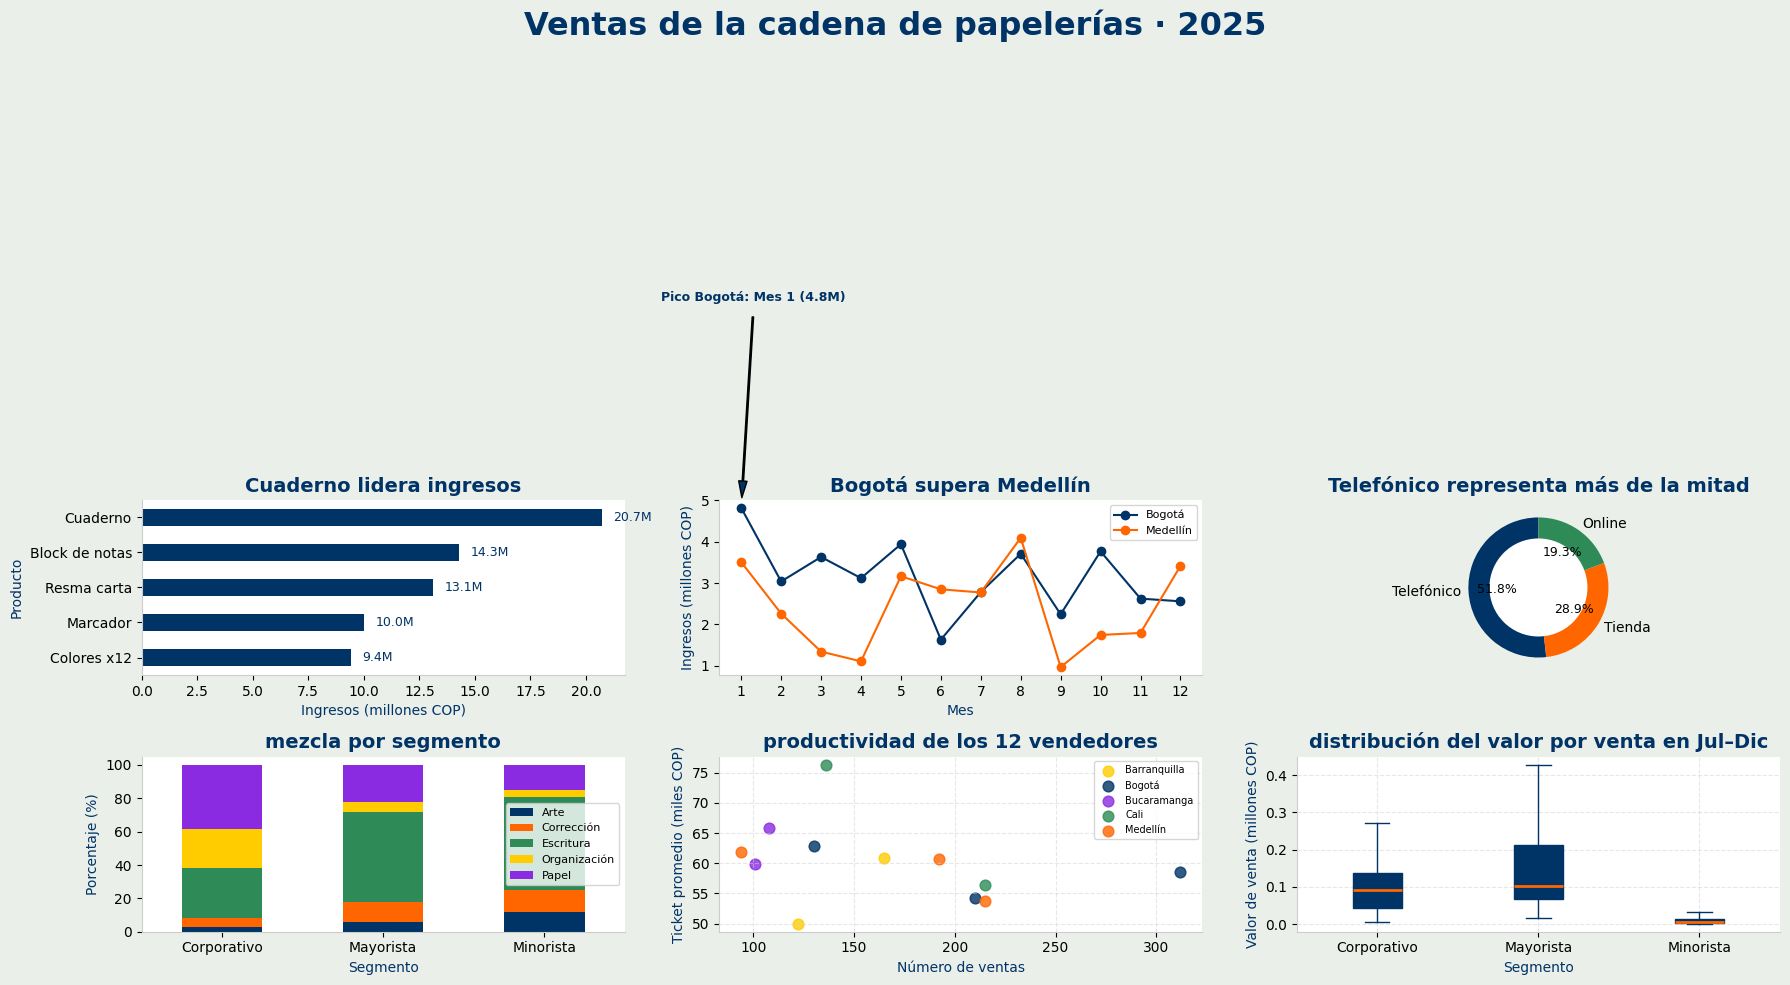

✔ v2 guardada · origen: Gemini


In [204]:
prompt_v2 = prompt_v1 + """

AJUSTES: Después de revisar la primera versión queremos hacer estos cambios concretos:
1. Cambia la gráfica de pastel por una DONA sin perder los porcentajes por canal.
2. Aumenta el título general a 23 puntos y los títulos de paneles a 14 puntos.
3. Señala el mes en el que Bogotá tuvo su pico de ingresos con una anotación clara.
4. Usa un fondo verde grisáceo muy claro, conserva paneles blancos y un acento verde oscuro.
No modifiques ningún valor, nombre de ciudad, categoría ni el número de vendedores.
"""

prompt_v2 += """
CORRECCIÓN DEL CÓDIGO:
La versión anterior produjo un SyntaxError:
invalid syntax en la línea 40.

Genera nuevamente el código Python completo,
asegurándote de que todas las líneas tengan
una sintaxis válida.

Devuelve únicamente código Python ejecutable,
sin explicaciones ni bloques Markdown.

Conserva exactamente los nombres 'Bogotá' y
'Medellín', con sus tildes.

Mantén las seis gráficas y todos los valores
originales. No cambies los cálculos.

En las etiquetas de ingresos muestra millones
correctamente: 20712345 pesos son 20.7 millones,
no 20712345 millones.

Aplica los cuatro ajustes de diseño solicitados.
"""

embellecer(prompt_v2, "v2", modelo="gemini-3.5-flash-lite")


### Ejercicio 10 *(opcional)* · Tercera versión
No es obligatoria. Ya se conservan las versiones v1 y v2 para comparar y escoger la mejor.


In [205]:
# Ejercicio 10 opcional: no se requiere una tercera versión.


In [206]:
# ✅ Verificación
assert len(VERSIONES) >= 2, "Debes tener al menos dos versiones de tu figura (v1 y v2)"
print("Versiones guardadas:", list(VERSIONES), "· Parte C correcta ✔")

Versiones guardadas: ['v1', 'v2'] · Parte C correcta ✔


---
# Parte D · Elige tu favorita y publícala
### Ejercicio 11 · Tu dashboard final y tus conclusiones
Mira tus versiones y **elige la que más te guste**. Luego escribe **3 hallazgos**: frases cortas con **cifras reales** sacadas de tus tablas. Se mostrarán debajo de tu dashboard.

*Ejemplo de hallazgo:* "Bogotá genera el 32 % de los ingresos de la cadena."

In [207]:
# Elegimos la segunda versión por la dona y los textos más claros.
figura_elegida = "v2"

# Cifras verificadas directamente con las tablas de las secciones anteriores.
hallazgos = [
    "El canal Telefónico facturó $61.450.716, el 51.8 % de los ingresos totales.",
    "Bogotá generó $37.847.614, el 31.9 % de los ingresos de la cadena.",
    "Cuaderno fue el producto líder: $20.712.345 de ingresos durante 2025."
]


In [208]:
# ✅ Verificación
assert figura_elegida in VERSIONES, f"No existe la versión {figura_elegida}: revisa figura_elegida"
assert len(hallazgos) == 3 and all(len(h) > 25 and "ESCRIBE AQUÍ" not in h for h in hallazgos), "Escribe tus 3 hallazgos con cifras"
print("Ejercicio 11 correcto ✔")

Ejercicio 11 correcto ✔


### Tu dashboard final
Ejecuta la celda: muestra la versión que elegiste y tus tres hallazgos. **Esta es la salida que se verá en GitHub.**

Dashboard elegido: v2 · Gemini


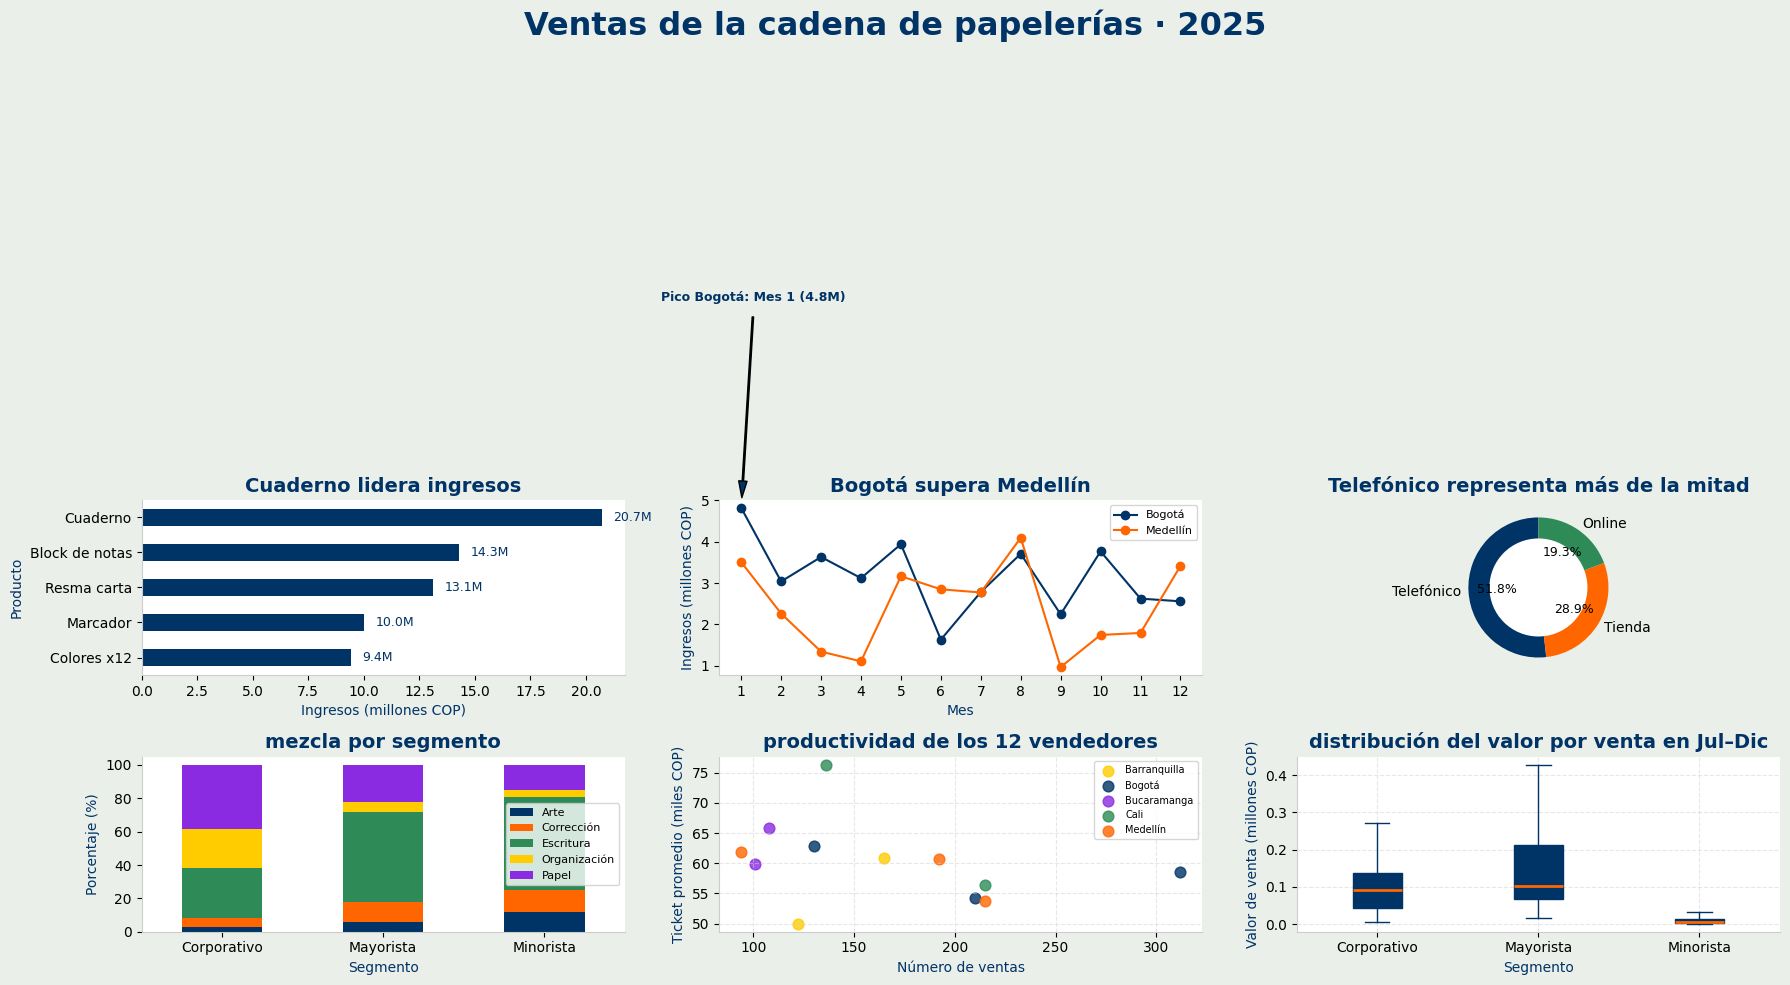

Hallazgos basados en los registros:
• El canal Telefónico facturó $61.450.716, el 51.8 % de los ingresos totales.
• Bogotá generó $37.847.614, el 31.9 % de los ingresos de la cadena.
• Cuaderno fue el producto líder: $20.712.345 de ingresos durante 2025.


In [209]:
print("Dashboard elegido:", figura_elegida, "·", ORIGEN_VERSION[figura_elegida])
mostrar(figura_elegida)
print("Hallazgos basados en los registros:")
for h in hallazgos:
    print("•", h)


### Ejercicio 12 · Publica tu notebook en GitHub
GitHub muestra los notebooks **con sus figuras**, así que tu notebook publicado es tu dashboard. Solo necesitas una cuenta gratuita en [github.com](https://github.com).

**Antes de publicar:**
- Ejecuta todo el notebook de arriba abajo (*Entorno de ejecución → Ejecutar todo*) para que las figuras queden guardadas en las salidas.
- **Nunca escribas tu API key dentro de una celda.** Los *Secrets* de Colab no se guardan en el notebook y por eso son seguros; el repositorio será público.

**Pasos:**
1. **Crea el repositorio:** botón **New** → nombre `mi-dashboard-ventas` → **Public** → *Create repository*.
2. **Guarda el notebook en GitHub.** Opción A: en Colab, *Archivo → Guardar una copia en GitHub*, autoriza, elige tu repositorio y acepta. Opción B: *Archivo → Descargar → .ipynb* y, en el repositorio, **Add file → Upload files** y arrastra el archivo.
3. **Abre el notebook en el repositorio** (haz clic en el archivo `.ipynb`): GitHub lo dibuja con tus figuras.
4. **Copia el enlace** de la barra del navegador. Debe verse así: `https://github.com/TU-USUARIO/mi-dashboard-ventas/blob/main/NOMBRE.ipynb`
5. **Compruébalo:** ábrelo en una ventana de incógnito. Si lo ves sin iniciar sesión, está público.

**Si no se ven las figuras:** vuelve a Colab, ejecuta todo y guarda de nuevo. Si GitHub dice *Unable to render code block*, recarga la página unos segundos después.

---
### Reflexión sobre prompts y mejoras

**Prompts utilizados:** `prompt_v1` y `prompt_v2` están escritos en el notebook con las cinco secciones exigidas por la guía. El segundo añade ajustes de diseño específicos.

**Tres ajustes solicitados para la segunda versión:**

1. Pedimos cambiar el gráfico circular por una dona para visualizar más claramente las participaciones sin perder los porcentajes.
2. Pedimos aumentar el tamaño de los títulos para mejorar la lectura de los seis paneles desde una pantalla de presentación.
3. Pedimos resaltar el valor máximo de Bogotá en el gráfico mensual y mantener intactas las cifras de las tablas.

**Verificación:** las 2.000 ventas, los totales por producto, canal y ciudad y el filtro de 1.050 ventas de Jul–Dic se validan antes de dibujar. Si en la salida de la Parte C aparece *previsualización local*, no se ha ejecutado Gemini; para acreditar esa iteración, agrega `GEMINI_API_KEY` en Colab y vuelve a ejecutar los prompts.

**Entrega pendiente:** cuando esté revisado, publicar el `.ipynb` en un repositorio público de GitHub y entregar su enlace.


### Reflexión sobre el uso de Gemini

1. En la primera versión, Gemini presentó algunos errores con los nombres de las ciudades y el formato de los ingresos.
2. Mejoramos los prompts indicando que debía respetar las tildes de Bogotá y Medellín, mantener las cifras originales y mostrar correctamente los valores en millones.
3. En la segunda versión solicitamos cambios en los colores, tamaños de letra y gráficos para mejorar la presentación, aunque algunas leyendas todavía se superponen.